# Mean-field bond model

Starting point: a `morse_parameters/<formula>_<crystal>.json` file already calibrated by `hessian_to_morse_parametrization.ipynb` for one (reference) volume.

Pipeline:

1. Load the structure, the Morse parameters, and turn them into bonding potentials.
2. Load the Hessian pre-computed using the same Morse parameters (needed for the bond-bond covariances).
3. Run the symmetry analysis on the supercell structure.
4. Compute the normalized bond pair covariances (`alphas`).
5. Assemble a `MeanFieldBondModel` and solve NVT at a single temperature (1000 K), plotting the mean-field bond density.
6. Sweep NVT and NPT over a range of 10 temperatures with `store_shell_details=False`, and plot `U_ah`, `T_vir`, and `P` vs. `T`.

This notebook lives at `examples/mean_field_bond_model/`, with structures under `examples/structures/<formula>_<crystal>/`, Hessian files under `examples/morse_hessians/<formula>_<crystal>/`, Morse parameters under `examples/hessian_to_morse_parametrization/morse_parameters/<formula>_<crystal>.json`, and MD reference data under `examples/md_data/<formula>_<crystal>/`. Results are written to `data/<formula>_<crystal>/` and `plots/<formula>_<crystal>/`.

Set `prefix` below to any of `Al_fcc`, `Fe_bcc`, `Mg_hcp`, `AlFe_B2`, `AlFe3_D0_3` or `Al2FeNi_L2_1`. Runtime: well under a minute for Al (fcc) on a laptop.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ase.io import read

import mean_field_bond_model.covariances as mf_covariances
import mean_field_bond_model.hessian as mf_hessian
import mean_field_bond_model.md as mf_md
import mean_field_bond_model.mean_field as mf_mean_field
import mean_field_bond_model.morse as mf_morse
import mean_field_bond_model.plot as mf_plot
import mean_field_bond_model.symmetry as mf_symmetry

## Settings

`n_shells`, `supercell` and `displacement` are looked up per system from `system_settings`, so that they match the Morse parameters, the pre-computed Morse Hessian and the MD bond-density grid.

`n_fine` / `n_coarse` and the temperature ranges below are reasonable starting points for a bulk fcc metal like Al; adjust to your system (in particular, `n_coarse` trades effective-potential accuracy for solve speed).

In [2]:
prefix = "Al_fcc"

# Per-system settings that must match the pre-computed inputs: the number of
# distance shells the Morse parameters were calibrated with, the supercell the
# Morse Hessian was computed on, and the half-width (Angstrom) of the MD
# bond-density grid.
system_settings = {
    "Al_fcc": {"n_shells": 3, "supercell": 5, "displacement": 1.0},
    "Fe_bcc": {"n_shells": 3, "supercell": 6, "displacement": 0.7},
    "Mg_hcp": {"n_shells": 3, "supercell": 5, "displacement": 1.0},
    "AlFe_B2": {"n_shells": 2, "supercell": 6, "displacement": 0.6},
    "AlFe3_D0_3": {"n_shells": 2, "supercell": 4, "displacement": 0.6},
    "Al2FeNi_L2_1": {"n_shells": 2, "supercell": 4, "displacement": 0.6},
}
n_shells = system_settings[prefix]["n_shells"]
supercell = system_settings[prefix]["supercell"]
displacement = system_settings[prefix]["displacement"]

structure_path = Path(f"../structures/{prefix}/{prefix}.data")
morse_params_path = Path(
    f"../hessian_to_morse_parametrization/morse_parameters/{prefix}.json"
)
hessian_path = Path(f"../morse_hessians/{prefix}/{prefix}.npz")
md_bond_data_path = Path(f"../md_data/{prefix}/{prefix}_1000K_bond.npz")
md_thermo_nvt_data_path = Path(f"../md_data/{prefix}/{prefix}_thermo_nvt.csv")
md_thermo_npt_data_path = Path(f"../md_data/{prefix}/{prefix}_thermo_npt.csv")
data_dir = Path(f"data/{prefix}")
plot_dir = Path(f"plots/{prefix}")
data_dir.mkdir(parents=True, exist_ok=True)
plot_dir.mkdir(parents=True, exist_ok=True)

# bond grid / mean-field settings
# fine grid points per axis (bond-density resolution)
n_fine = 51
# coarse grid points per axis (effective-potential integration)
n_coarse = 15
# None -> exact commensurate q-mesh (recommended)
mesh_size = None
use_coarse = True

# temperatures, K
temperature = 1000.0
temperature_sweep = np.linspace(100.0, 1000.0, 10)

## Structure, Morse parameters, bonding potentials

In [3]:
structure = read(structure_path, format="lammps-data")
morse_params = mf_morse.load_morse_params(morse_params_path)
bonding_potentials = mf_morse.build_bonding_potentials(morse_params)
morse_params

{0: {'species': 'Al',
  'basis_sites': [0],
  'shells': {1: {'D_e': 0.4072,
    'a': 1.1766,
    'r_e': 2.8604,
    'target_species': 'Al'},
   2: {'D_e': 0.0, 'a': 0.0, 'r_e': 4.0453, 'target_species': 'Al'},
   3: {'D_e': 0.0, 'a': 0.0, 'r_e': 4.9544, 'target_species': 'Al'}}}}

## Reference-volume Hessian

Here, we need the Hessian computed on the reference structure using the Morse bonding potentials (and not the empirical pair potential).

Since we do not want to run custom LAMMPS scripts here, we load the Morse-Hessians computed externally for the same Morse parameters.

In [4]:
ref_displaced, ref_disp_dict, ref_phonopy = (
    mf_hessian.generate_supercells_with_displacements(
        structure=structure,
        supercell=supercell,
        return_phonopy=True,
    )
)
supercell_structure = ref_disp_dict["supercell_structure"]
ref_hessian = np.load(hessian_path)["hessian"]
if len(ref_hessian) != len(supercell_structure):
    raise ValueError(
        f"The Hessian has {len(ref_hessian)} atoms but the supercell has "
        f"{len(supercell_structure)}; check system_settings[{prefix!r}]."
    )

## Symmetry analysis

Built on `supercell_structure`, the same structure the Hessian is indexed against.

In [5]:
symmetry_analysis = mf_symmetry.NeighborBondSymmetryAnalysis(
    structure=supercell_structure,
    n_shells=n_shells,
).analyze()

## Bond-bond covariances (alphas)

In [6]:
alphas = mf_covariances.BondPairCovarianceCalculator(
    structure=supercell_structure,
    symmetry_analysis=symmetry_analysis,
    hessian=ref_hessian,
    mesh_size=mesh_size,
).compute_alphas()

## Assemble the mean-field model

In [7]:
mfbm = mf_mean_field.MeanFieldBondModel(
    structure=supercell_structure,
    bonding_potentials=bonding_potentials,
    symmetry_analysis=symmetry_analysis,
    alphas=alphas,
    use_coarse=use_coarse,
    n_coarse=n_coarse,
    n_fine=n_fine,
    # output grid, must match the MD grid
    displacement=displacement,
    n_output=n_fine,
)

## Single-temperature NVT (1000 K)

In [8]:
result_mfbm = mfbm.run_nvt(temperatures=temperature)

In [9]:
mfbm_bond_grids, mfbm_bond_densities = mfbm.bond_data(result_mfbm)
mf_md.save_md_bond_data(
    mfbm_bond_grids,
    mfbm_bond_densities,
    data_dir / f"{prefix}_{temperature:.0f}K_bond.npz",
)

In [10]:
md_bond_grids, md_bond_densities = mf_md.load_md_bond_data(
    path=md_bond_data_path
)

Wyckoff site: 0; shell: 1


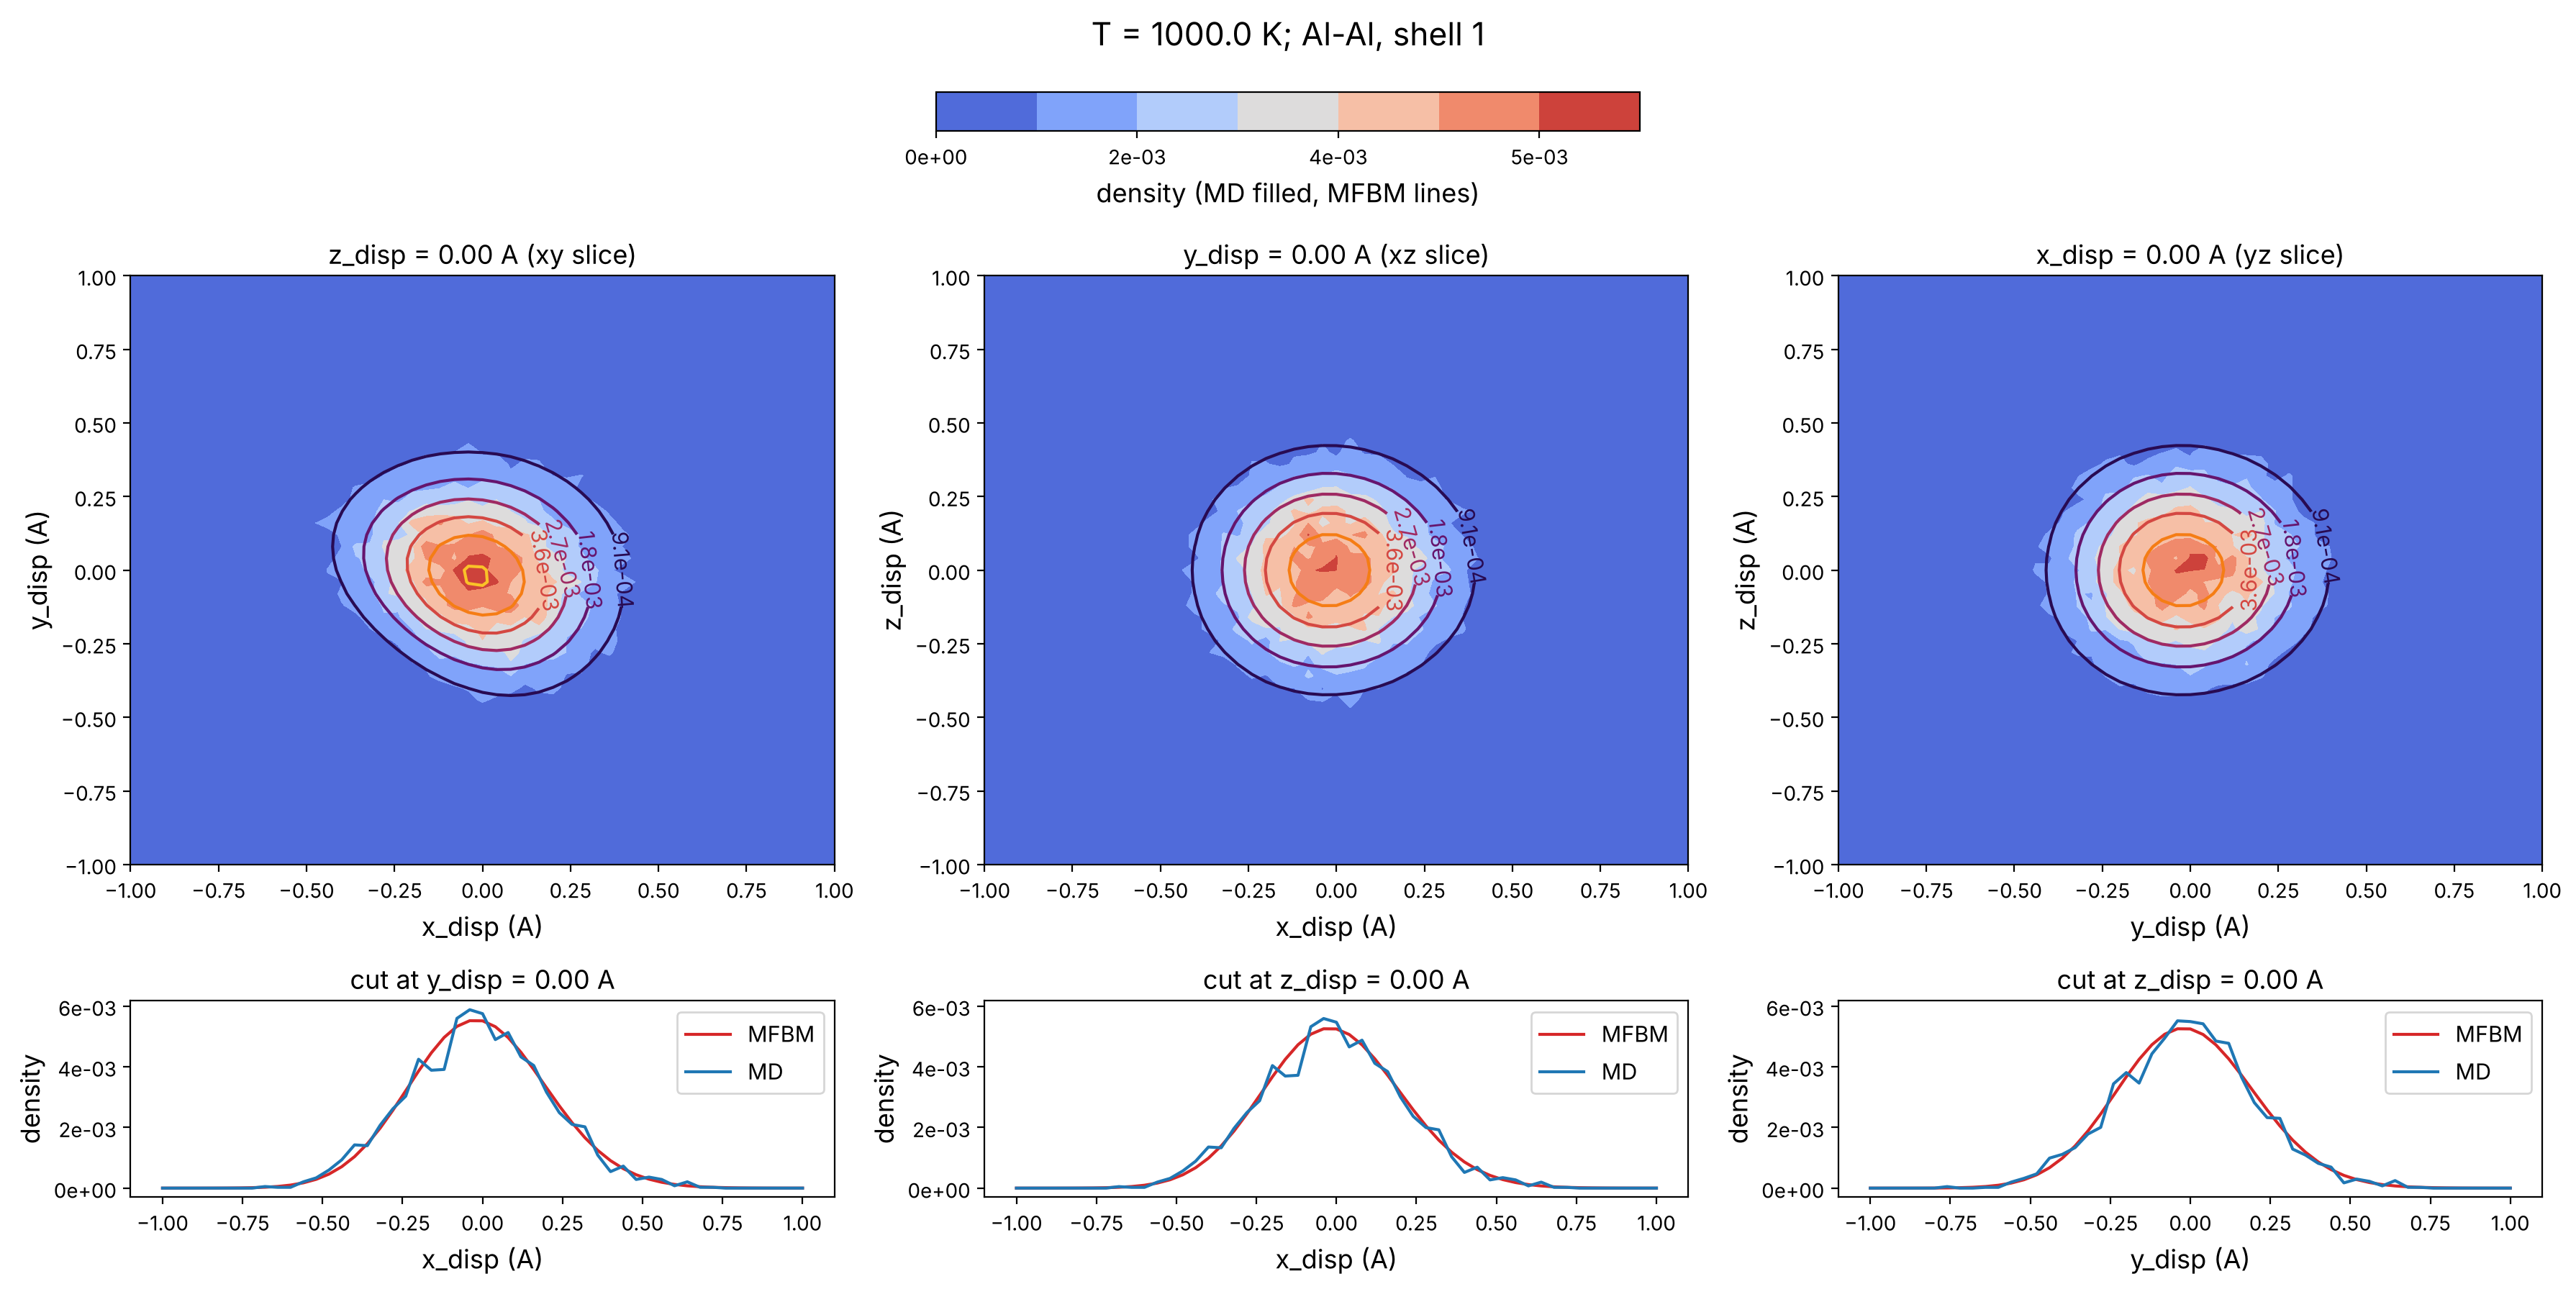

Wyckoff site: 0; shell: 2


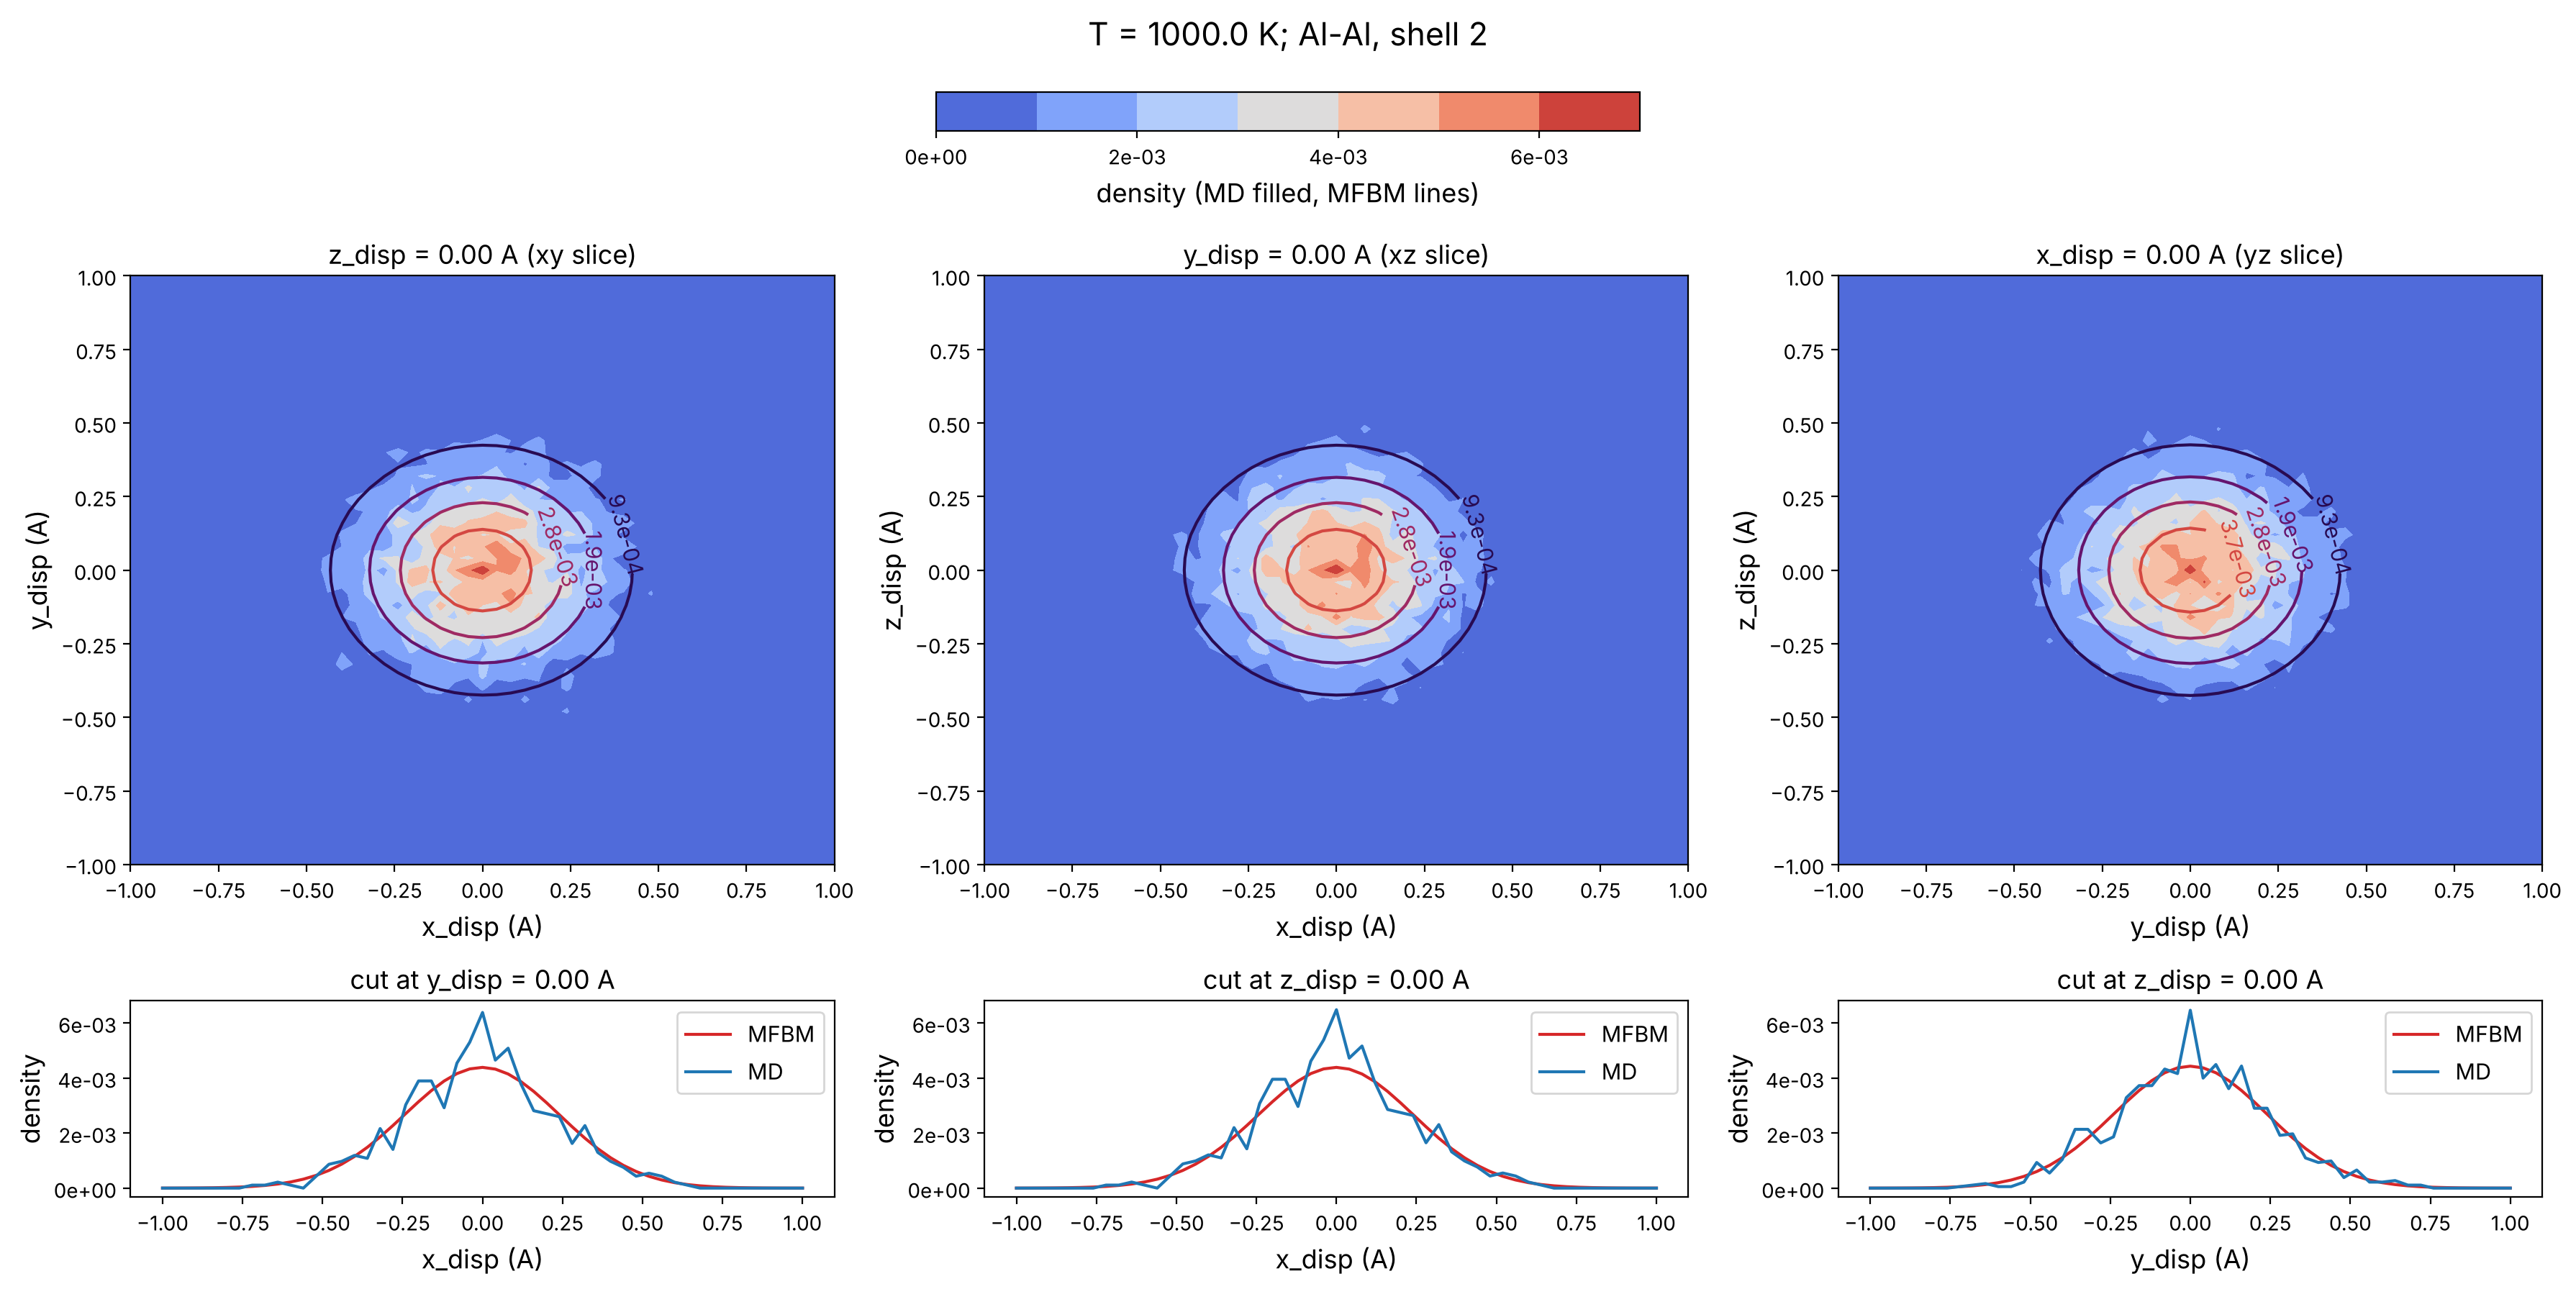

Wyckoff site: 0; shell: 3


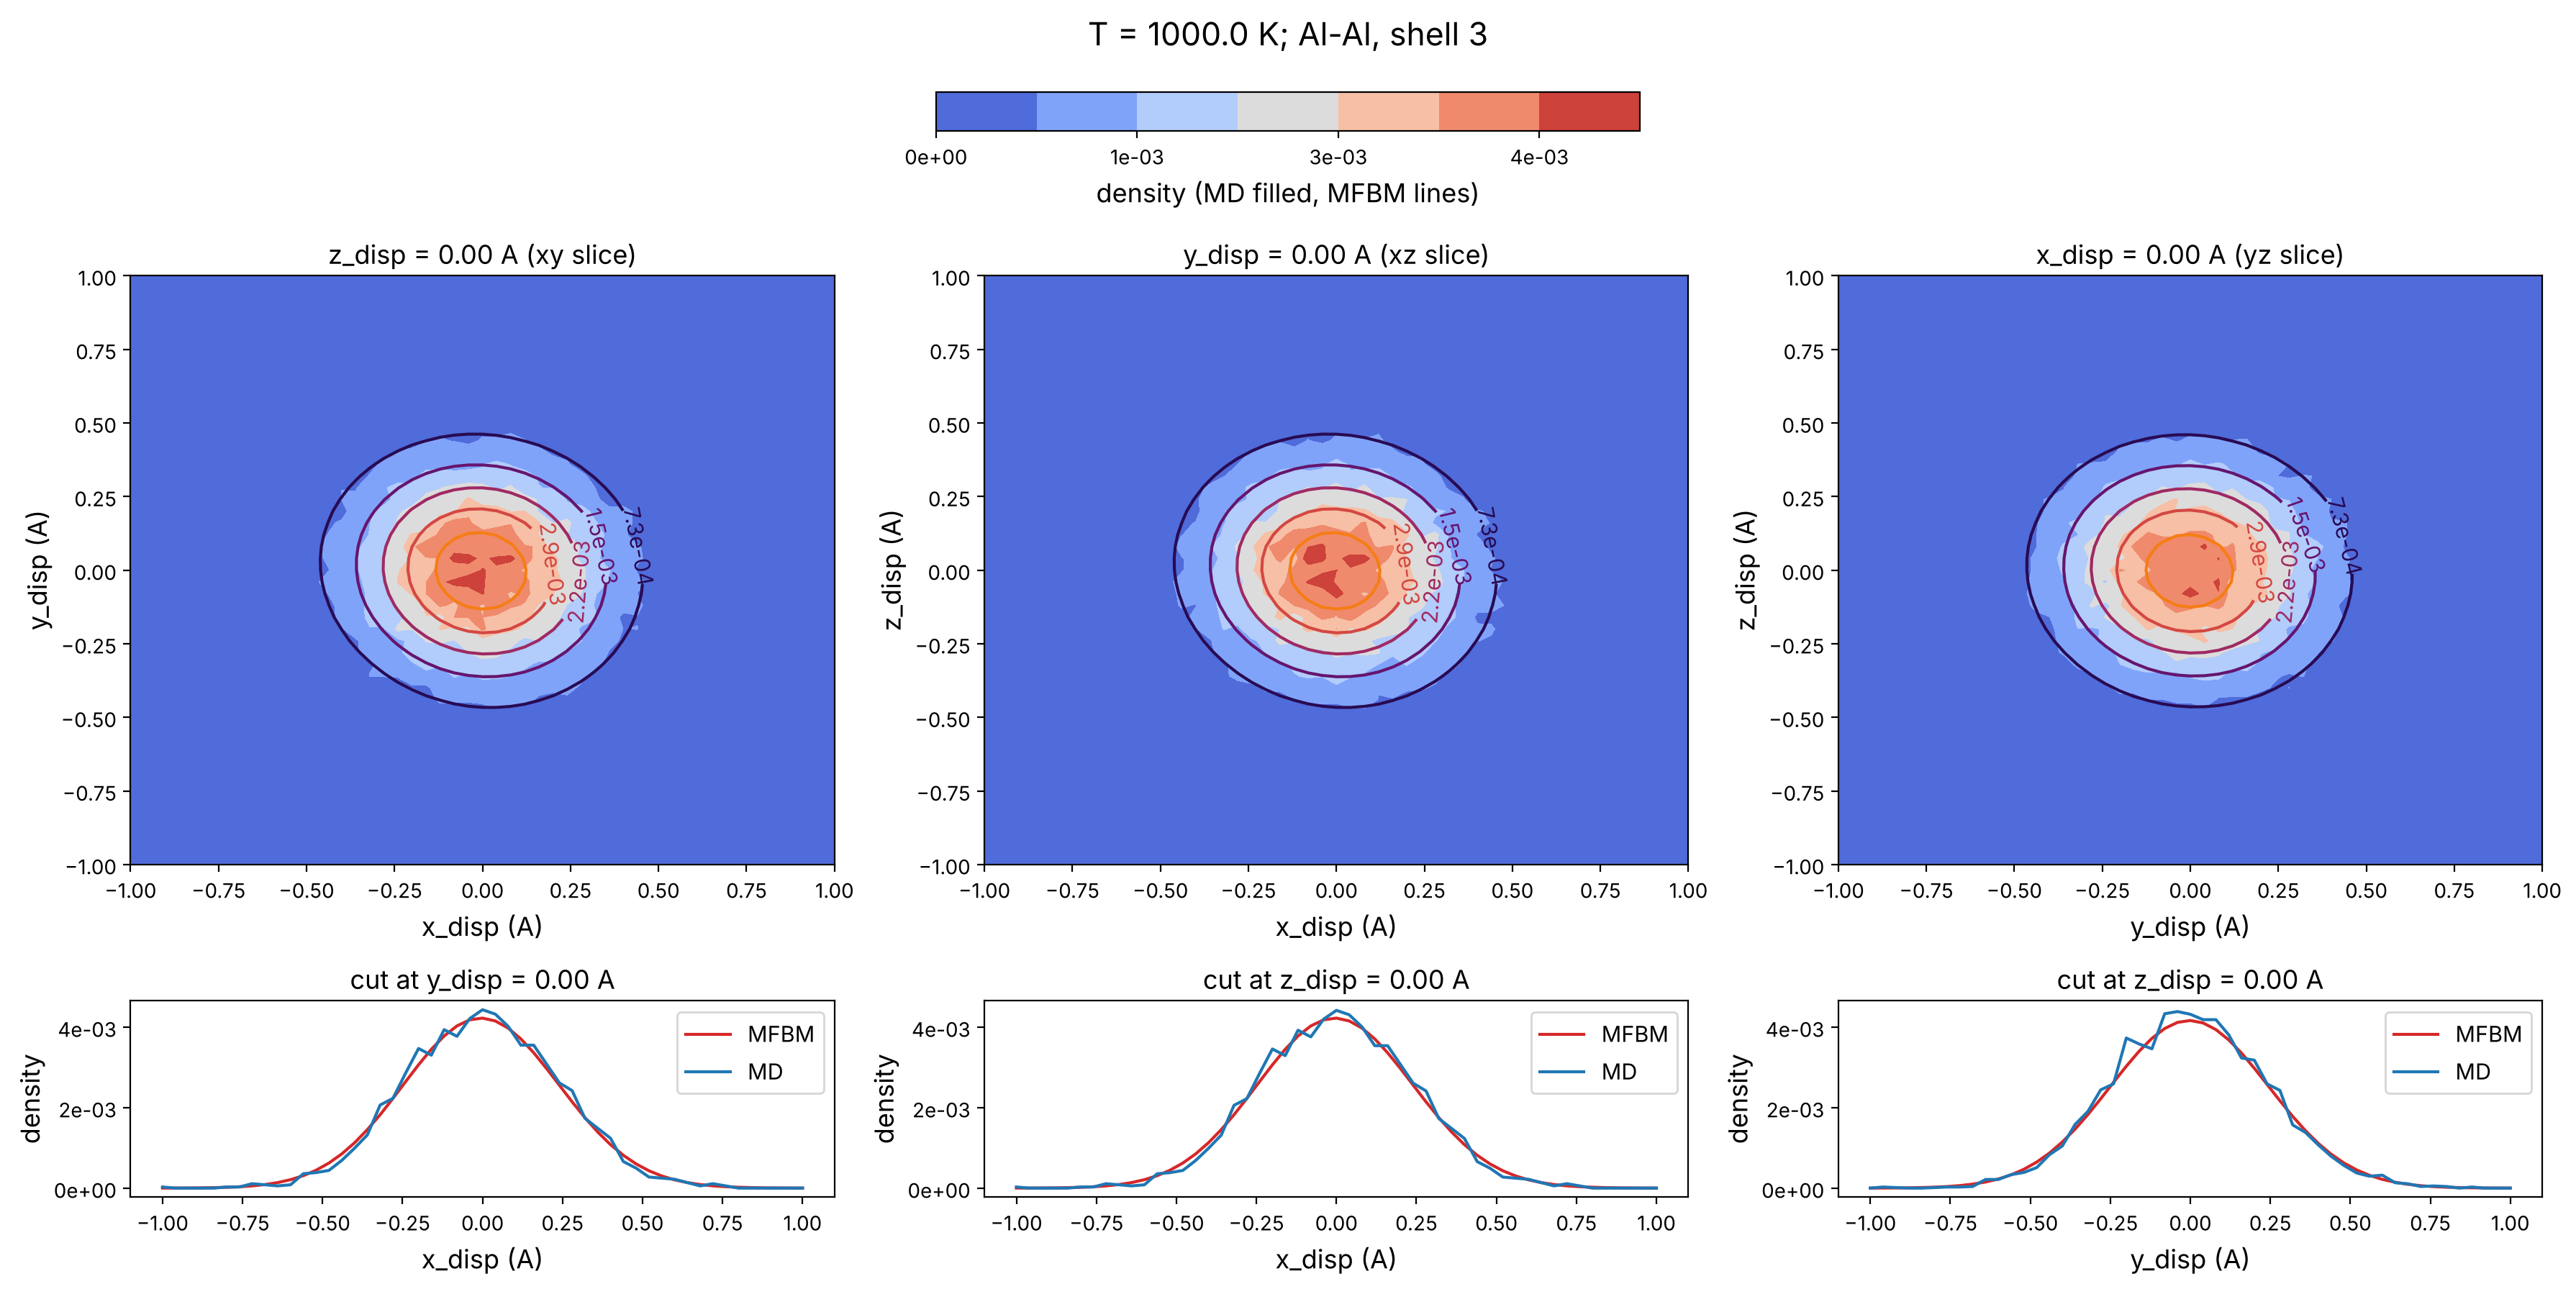

In [11]:
disps = np.linspace(-displacement, displacement, n_fine)

for wyckoff_site, site in result_mfbm["Wyckoff_sites"].items():
    for shell, shell_result in site["shells"].items():
        print(f"Wyckoff site: {wyckoff_site}; shell: {shell}")
        fig, axes = mf_plot.plot_bond_density_slices(
            disps=disps,
            rho_mfbm=shell_result["bond_density"],
            rho_md=md_bond_densities[wyckoff_site][shell],
            temperature=temperature,
            label=(
                f"{site['species']}-{shell_result['target_species']}, "
                f"shell {shell}"
            ),
            n_levels=7,
        )
        fig.savefig(
            plot_dir / f"rho_wyckoff_site_{wyckoff_site}_shell_{shell}.png",
            dpi=100,
        )
        plt.show()

## NVT & NPT temperature sweeps (aggregates only)

`store_shell_details=False` drops each basis site's `"shells"` sub-dict (the bond-density arrays and per-shell diagnostics), keeping only the basis-site/crystal-level aggregates.

In [12]:
def build_mfb_summary_table(
    sweep_result,
    U_units="meV/atom",
    P_units="bar",
):
    """
    Flatten a MeanFieldBondModel.run_nvt / run_npt sweep into one row per
    temperature, column-compatible with plot_thermo_sweep and the MD reference
    table.

    Returns
    -------
    df : pandas.DataFrame
        Columns: Temperature, U_ah [<U_units>], F_ah [<U_units>], P
        [<P_units>], eps, T_vir [K]
    """
    scale = {"meV/atom": 1000.0, "eV/atom": 1.0}.get(U_units)
    if scale is None:
        raise ValueError(
            f"Unsupported U_units {U_units!r}; use 'meV/atom' or 'eV/atom'."
        )

    return pd.DataFrame(
        {
            "Temperature": [r["temperature"] for r in sweep_result],
            f"U_ah [{U_units}]": [r["U_ah"] * scale for r in sweep_result],
            f"F_ah [{U_units}]": [r["F_ah"] * scale for r in sweep_result],
            f"P [{P_units}]": [r["P"] for r in sweep_result],
            "eps": [r["eps"] for r in sweep_result],
            "T_vir [K]": [r["T_vir"] for r in sweep_result],
        }
    )

In [13]:
nvt_sweep_results = mfbm.run_nvt(
    temperatures=temperature_sweep,
    store_shell_details=False,
)

In [14]:
df = build_mfb_summary_table(nvt_sweep_results)
df.to_csv(data_dir / f"{prefix}_thermo_nvt.csv", index=False)

In [15]:
# This bit can take a while
npt_sweep_results = mfbm.run_npt(
    temperatures=temperature_sweep,
    pressure=0.0,  # bar
    store_shell_details=False,
)

In [16]:
df = build_mfb_summary_table(npt_sweep_results)
df.to_csv(data_dir / f"{prefix}_thermo_npt.csv", index=False)

In [17]:
df

,Temperature,U_ah [meV/atom],F_ah [meV/atom],P [bar],eps,T_vir [K]
0,100.0,0.089394,-0.088860,0.000151,1.001760,99.999999
1,200.0,0.361841,-0.357574,0.000015,1.003564,200.000117
2,300.0,0.824116,-0.809404,0.000105,1.005403,300.000003
3,400.0,1.483529,-1.447784,0.000298,1.007279,400.000010
4,500.0,2.347975,-2.276329,0.000552,1.009192,500.000018
5,600.0,3.425992,-3.298851,0.000891,1.011144,600.000029
6,700.0,4.726825,-4.519372,0.001325,1.013138,700.000044
7,800.0,6.260504,-5.942141,0.001866,1.015174,800.000062
8,900.0,8.037955,-7.571654,0.002530,1.017255,900.000085
9,1000.0,10.071059,-9.412672,0.003330,1.019384,1000.000113


## NVT -- `U_ah`, `T_vir`, `P` vs. `T`

The crystal-level `T_vir` equals the target temperature *by construction*, so that panel is a self-consistency check.

In [18]:
def plot_thermo_sweep(
    df: "pd.DataFrame",
    ensemble_label: str,
    reference_df: "pd.DataFrame | None" = None,
    prefix: str | None = None,
    save: bool = False,
):
    """
    Plot U^ah, F^ah, T^vir (self-consistency check) and a fourth panel against
    temperature for one sweep. The fourth panel is the pressure P for NVT, or
    the lattice strain eps for NPT.

    Parameters
    ----------
    df : pandas.DataFrame
        MFB sweep results, one row per temperature, with columns "Temperature",
        "U_ah [meV/atom]", "F_ah [meV/atom]", "T_vir [K]", and either "P [bar]"
        (NVT) or "eps" (NPT).
    ensemble_label : str
        "NVT" or "NPT" (case-insensitive); also used in the title and saved
        filename.
    reference_df : pandas.DataFrame, optional
        Reference (e.g. MD) results, overlaid as black crosses with a shaded
        SEM band wherever the columns exist: "U_ah [meV/atom]", "F_ah
        [meV/atom]", and "P [bar]" or "eps", each with its "_sem" column.
    prefix : str, optional
        Subdirectory under "plots/" to save to. Required if save=True.
    save : bool, optional
        Save to f"plots/{prefix}/thermo_{ensemble_label.lower()}.png".
    """
    is_npt = ensemble_label.upper() == "NPT"
    fontsizes = mf_plot.DEFAULT_FONTSIZES
    df = df.sort_values("Temperature")
    T = df["Temperature"].to_numpy()

    panels = [
        (
            "U_ah [meV/atom]",
            "U_ah_sem [meV/atom]",
            r"$\mathcal{U}^{\mathrm{ah}}$ (meV/atom)",
            "Anharmonic internal energy",
            "tab:red",
        ),
        (
            "F_ah [meV/atom]",
            "F_ah_sem [meV/atom]",
            r"$\mathcal{F}^{\mathrm{ah}}$ (meV/atom)",
            "Anharmonic free energy",
            "tab:purple",
        ),
        (
            "T_vir [K]",
            None,
            r"$T^{\mathrm{vir}}$ (K)",
            "Virial temperature (self-consistency check)",
            "tab:blue",
        ),
        (
            ("eps", "eps_sem", r"$\epsilon$", "Lattice strain", "tab:green")
            if is_npt
            else (
                "P [bar]",
                "P_sem [bar]",
                r"$P$ (bar)",
                "Pressure",
                "tab:green",
            )
        ),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (col, sem_col, ylabel, title, color) in zip(axes.flat, panels):
        ax.plot(T, df[col].to_numpy(), "o-", color=color, label="MFB")
        if col == "T_vir [K]":
            ax.plot(
                T,
                T,
                "x--",
                color="k",
                linewidth=0.8,
                markersize=7,
                markeredgewidth=1.5,
                label=r"$T^{\mathrm{vir}} = T$",
            )
        elif reference_df is not None and col in reference_df.columns:
            ref = reference_df.sort_values("Temperature")
            ref_T = ref["Temperature"].to_numpy()
            mean = ref[col].to_numpy()
            sem = ref[sem_col].to_numpy()
            ax.plot(
                ref_T,
                mean,
                "x--",
                color="k",
                linewidth=0.8,
                markersize=7,
                markeredgewidth=1.5,
                label="MD",
            )
            ax.fill_between(
                ref_T, mean - sem, mean + sem, color="k", alpha=0.15
            )
        if len(ax.get_lines()) > 1:
            ax.legend(fontsize=fontsizes["legend"], frameon=False)
        ax.set_xlabel(r"$T$ (K)", fontsize=fontsizes["label"])
        ax.set_ylabel(ylabel, fontsize=fontsizes["label"])
        ax.set_title(title, fontsize=fontsizes["title"])
        ax.tick_params(
            axis="both", labelsize=fontsizes["tick"], direction="in"
        )
        ax.tick_params(axis="y", which="both", right=True, labelright=False)

    fig.suptitle(
        f"{prefix} -- {ensemble_label}".replace("_", " "),
        fontsize=fontsizes["suptitle"],
    )
    fig.tight_layout()
    if save:
        fig.savefig(
            Path(f"plots/{prefix}/thermo_{ensemble_label.lower()}.png"),
            dpi=100,
        )
    plt.show()

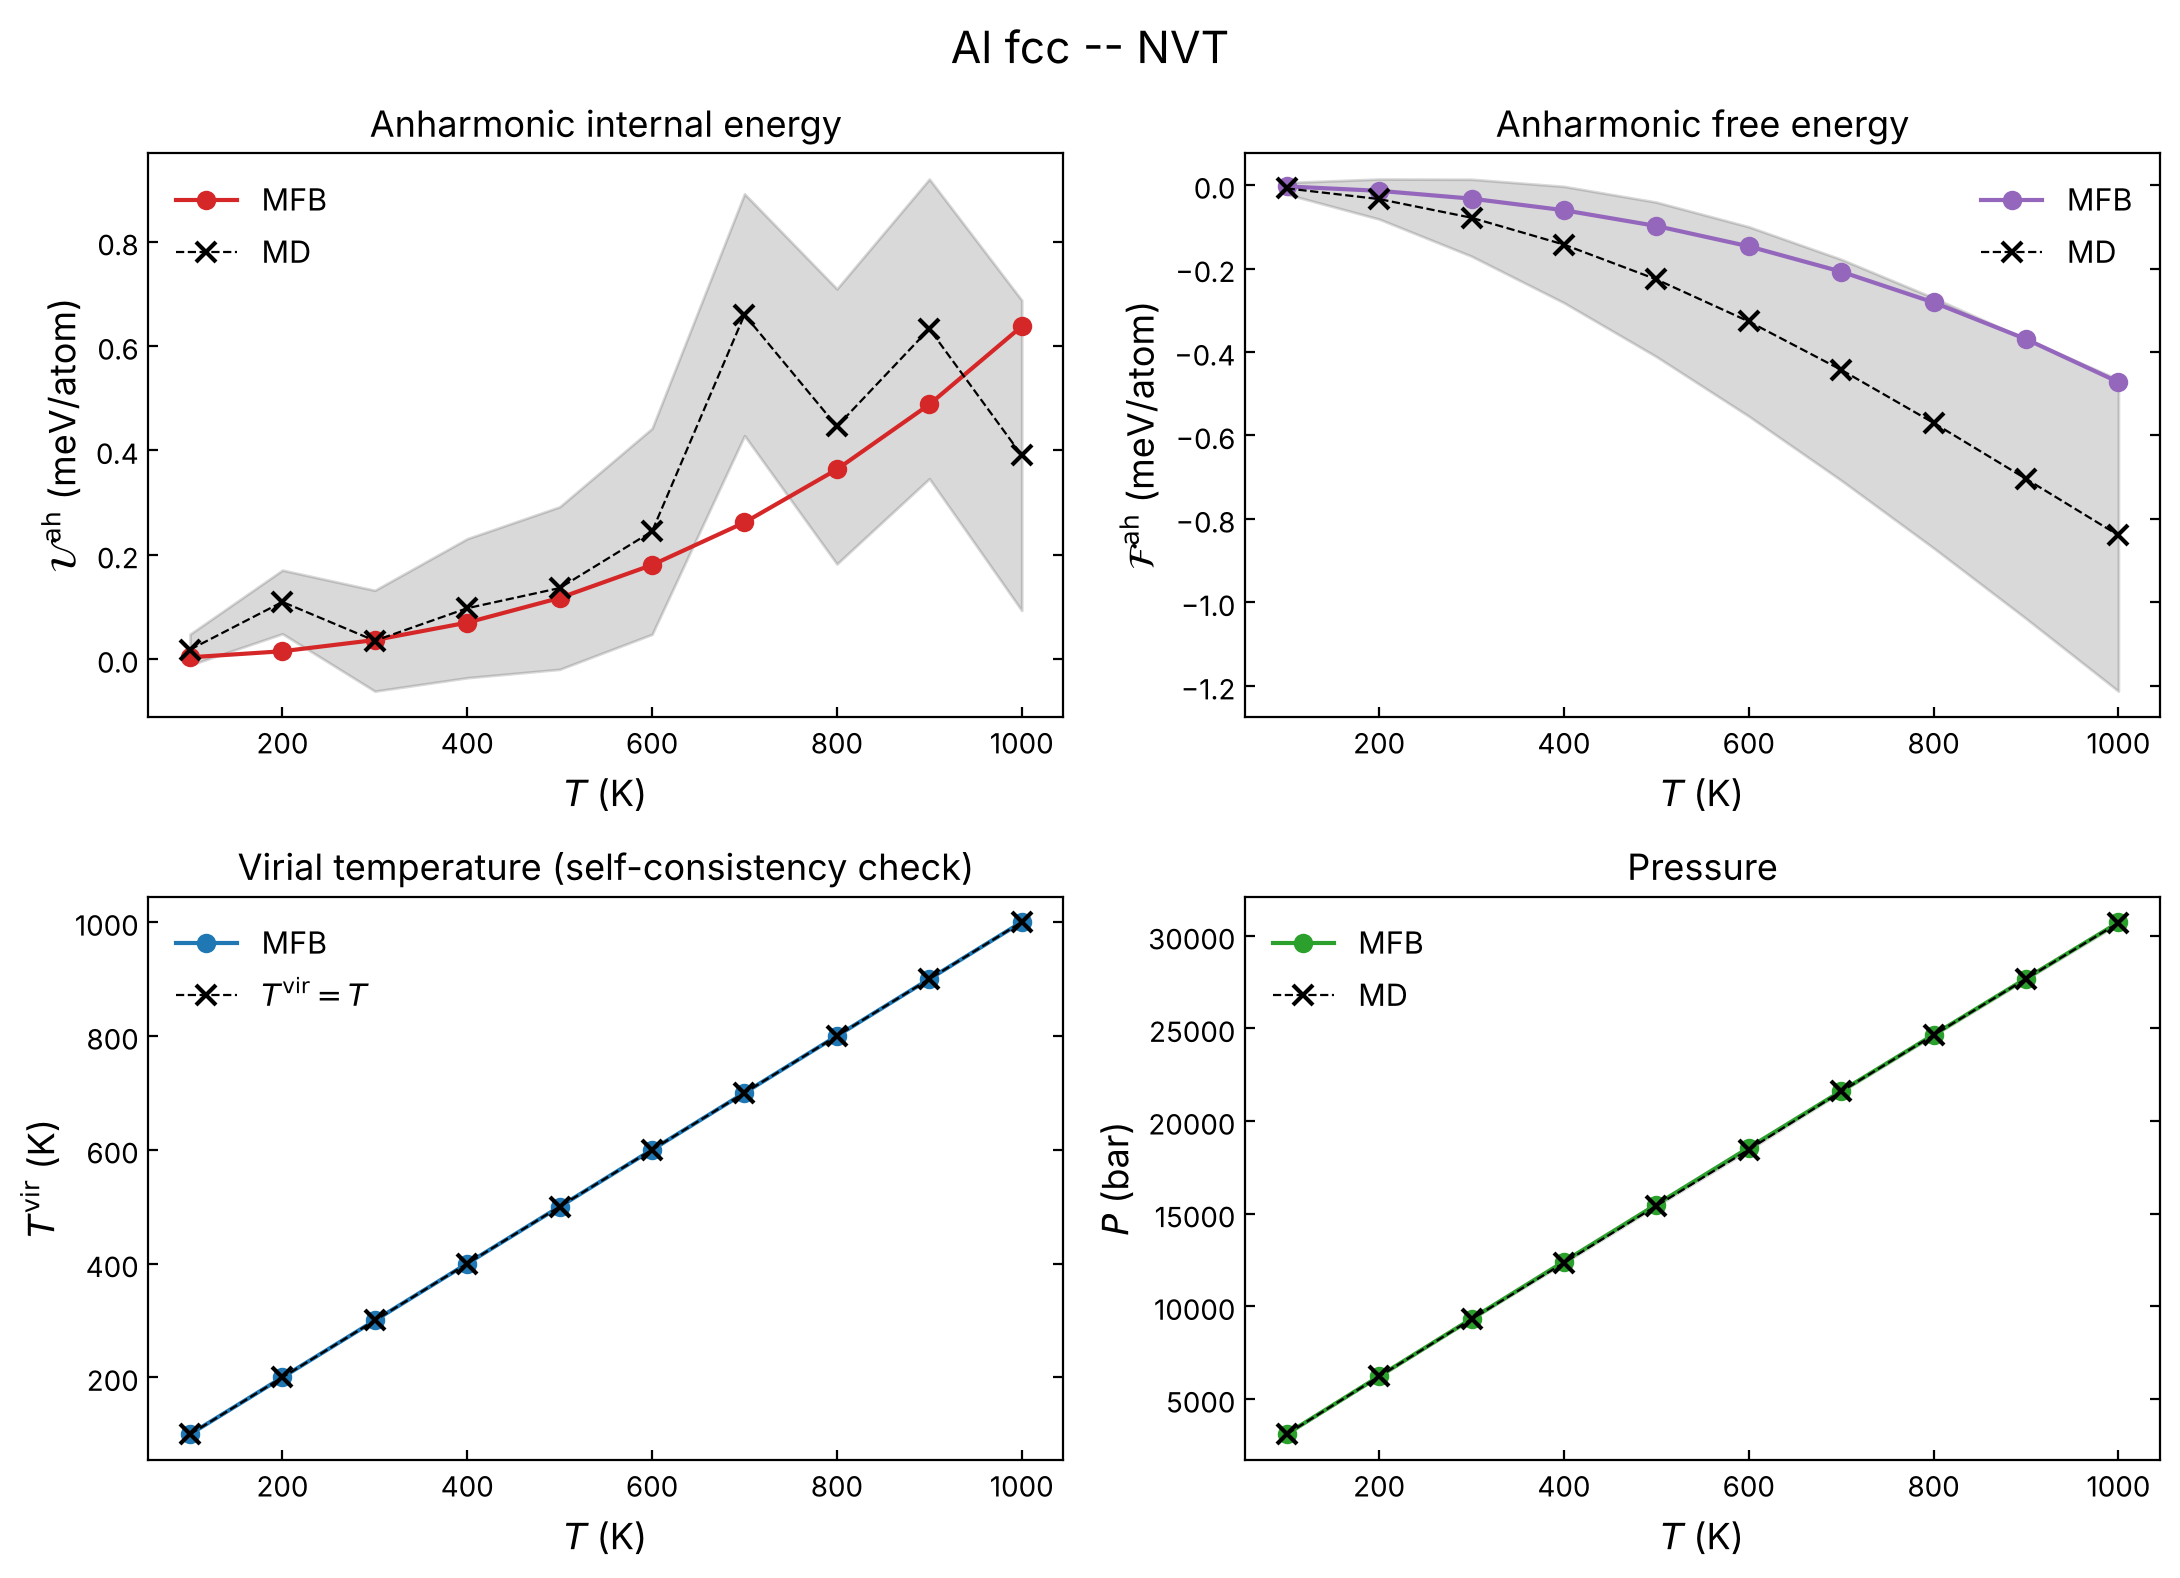

In [19]:
nvt_df = pd.read_csv(data_dir / f"{prefix}_thermo_nvt.csv")
nvt_ref = pd.read_csv(md_thermo_nvt_data_path)

plot_thermo_sweep(
    df=nvt_df,
    ensemble_label="NVT",
    reference_df=nvt_ref,
    prefix=prefix,
    save=True,
)

## NPT -- `U_ah`, `T_vir`, `eps` vs. `T`

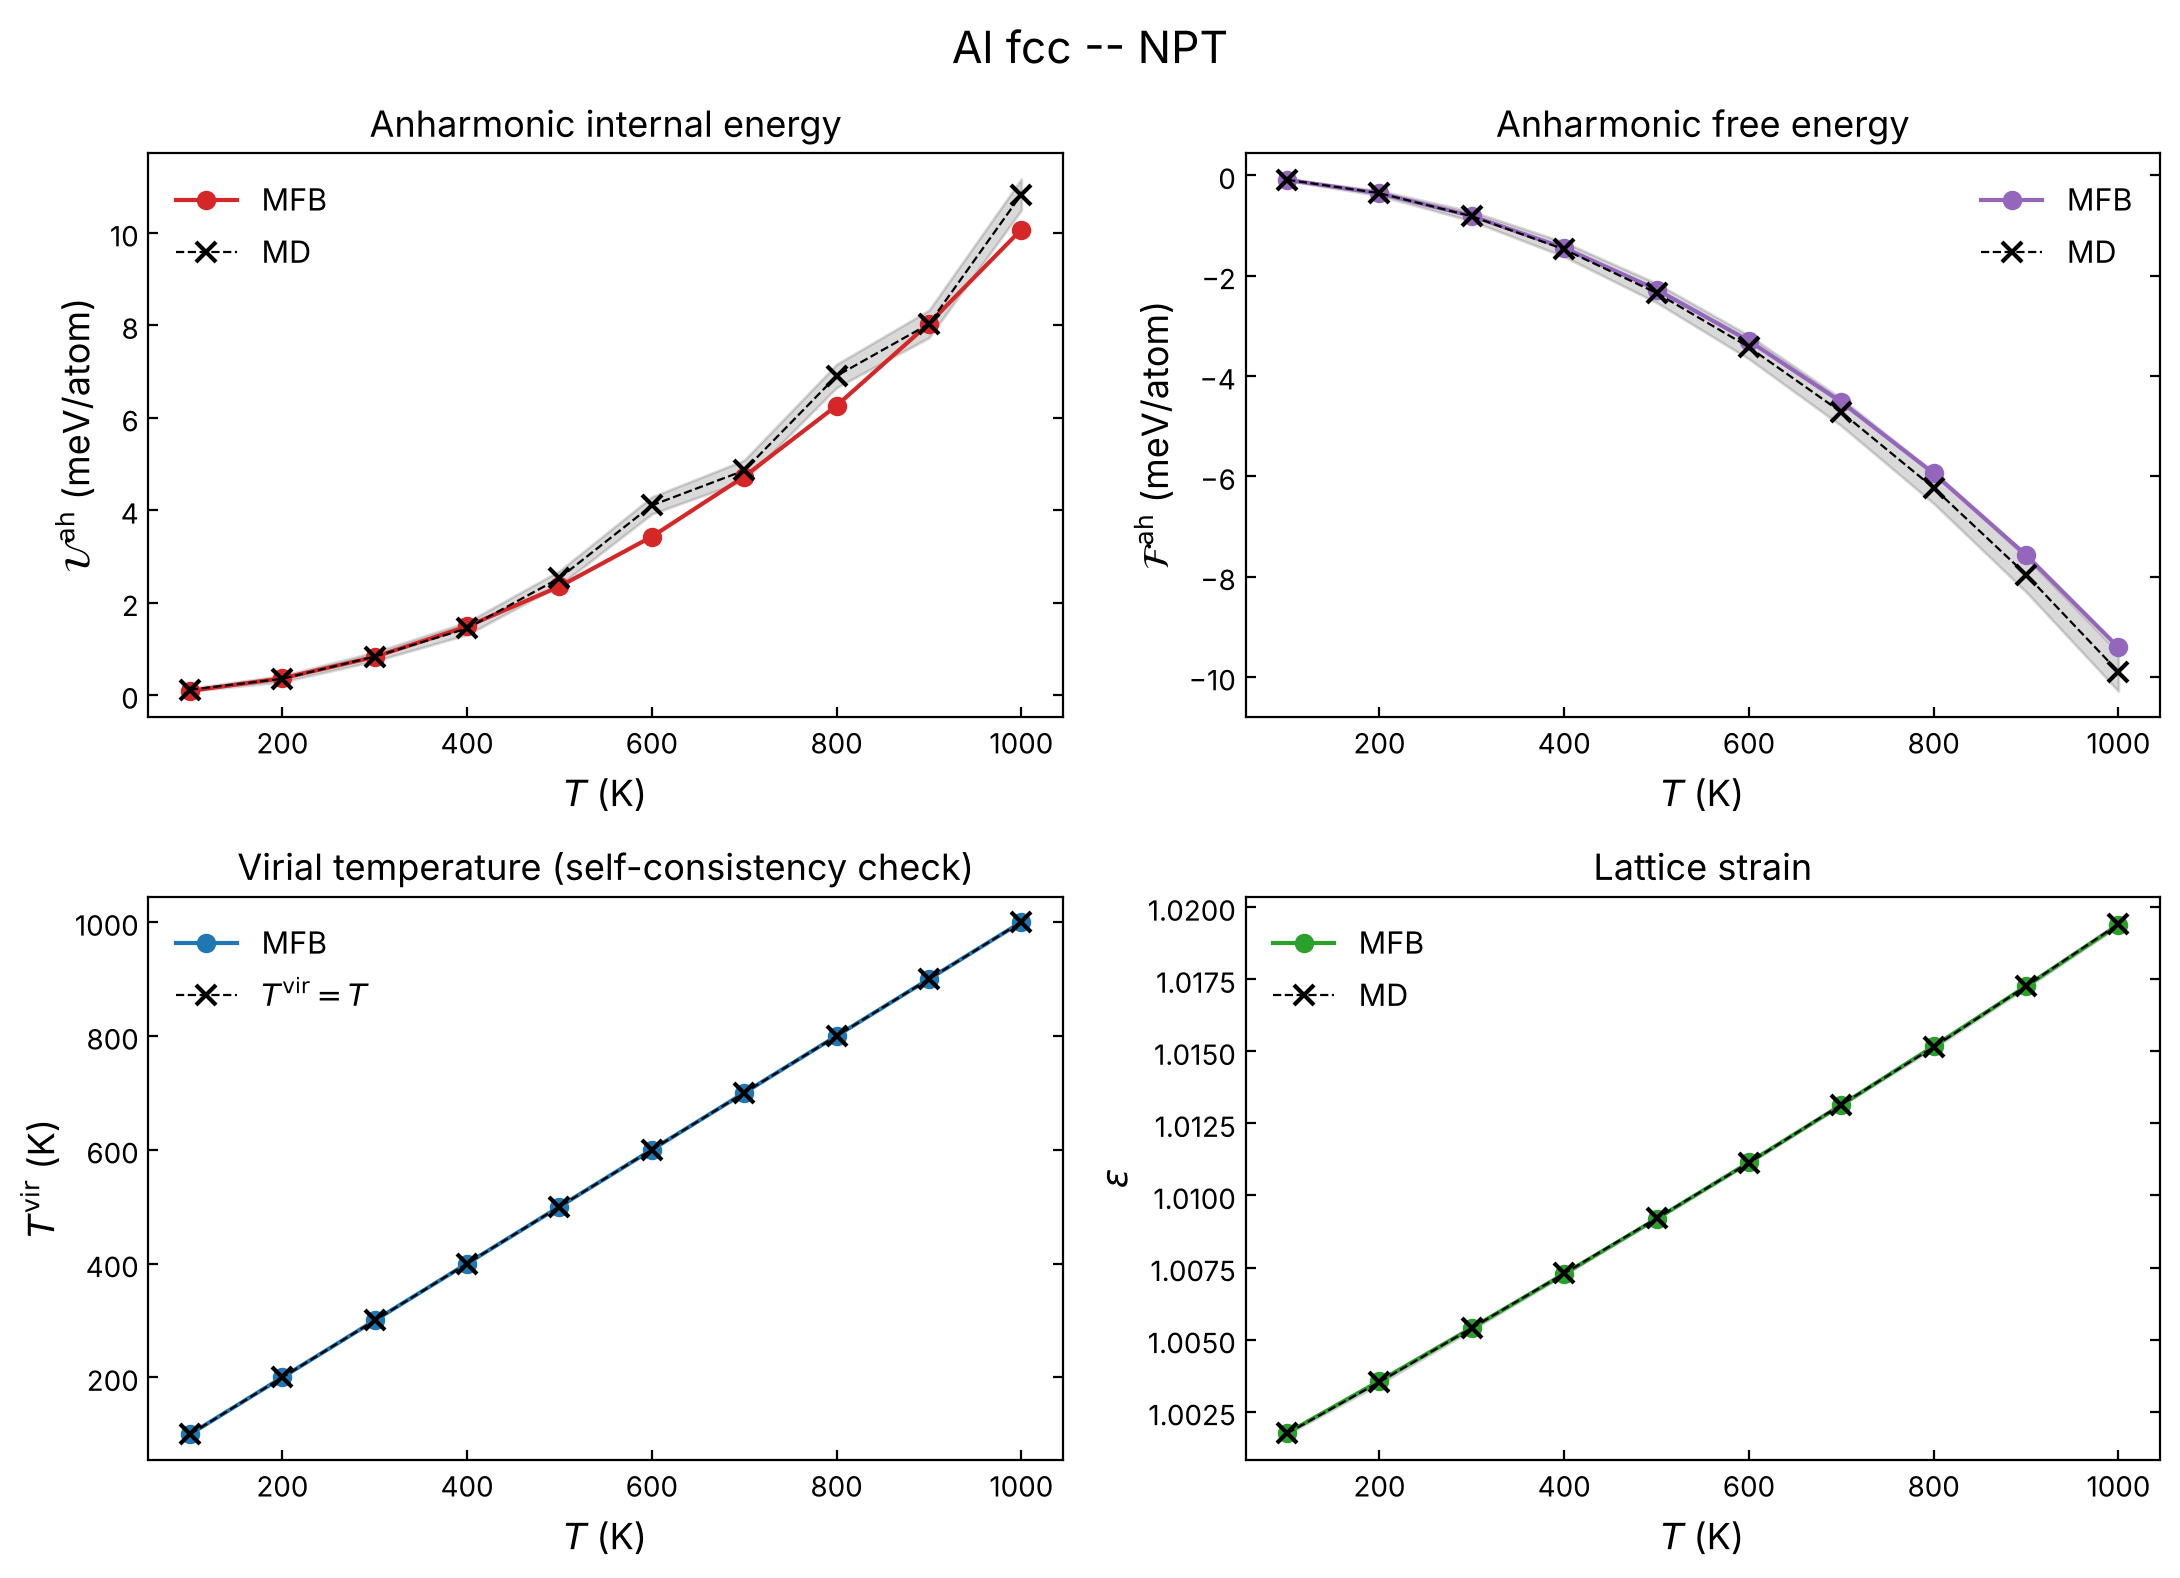

In [20]:
npt_df = pd.read_csv(data_dir / f"{prefix}_thermo_npt.csv")
npt_ref = pd.read_csv(md_thermo_npt_data_path)

plot_thermo_sweep(
    df=npt_df,
    ensemble_label="NPT",
    reference_df=npt_ref,
    prefix=prefix,
    save=True,
)